In [8]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import findiff

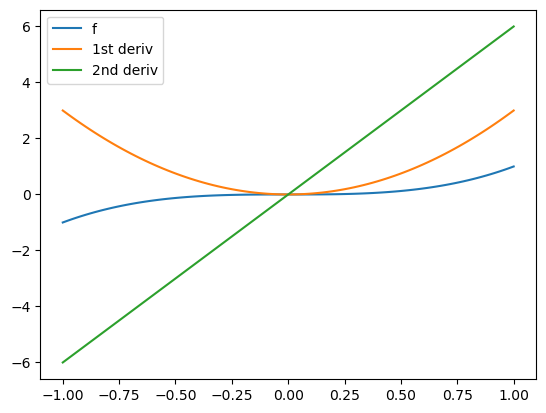

In [12]:
## playing, learning, yeah
x = np.linspace(-1,1,100) # defining the length lenght of the x axis.
dx = x[1] - x[0]
d_dx = findiff.Diff(0, dx) # arg 1 is the axis, so im deciding axis 0 is x, and dx is the difference (?)
# this is just the standard differential operator from calc class, differentiating once wrt x.
d2_dx2 = d_dx ** 2 # this is differentiating twice! we can just use exponentiation.
# lets test with some examples that are easy to understand.

f = x**3 # x cubed
df_dx = d_dx(f) # first derivative
d2f_dx2 = d2_dx2(f) # 2nd derivative

plt.plot(x,f,label = "f")
plt.plot(x,df_dx,label = "1st deriv")
plt.plot(x,d2f_dx2,label = "2nd deriv")

plt.legend()
plt.show()
# cool! that looks liek 3x^2 and 6x.

In [17]:
# lets make a more complitacted differential operator, as a warmup for black scholes.
# lets try the 3d cartesian laplacian
x_k = np.linspace(-1,1,100)
dx_k = x_k[1] - x_k[0] # im making a uniform  cubic grid of points, so we can reuse here.
d_dx = findiff.Diff(0, dx_k) 
d_dy = findiff.Diff(1, dx_k)
d_dz = findiff.Diff(2, dx_k)
del_sq = d_dx**2 + d_dy**2 + d_dz**2 #yep

X,Y,Z = np.meshgrid(x_k,x_k,x_k, indexing = "ij") # indexing is so that we get the correct axes applied.
f = np.sin(X)*np.cos(Y)*np.sin(Z)

lap_f = del_sq(f)

In [ ]:
#now lets try black scholes.
expiry = 10 # examples expiry date
strike = 3000 # strike price
t = np.linspace(0,expiry,100)
S = np.linspace(0,4*strike,100) # 4* gives  some room to breathe
bs_op = findiff.Diff()

In [2]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from findiff import Diff

K, r, sigma, T = 100.0, 0.05, 0.2, 1.0
N, M = 400, 200                      # space points, time steps
S = np.linspace(0, 4*K, N); dS = S[1] - S[0]
dt = T / M

D1 = Diff(0, dS).matrix((N,))
D2 = (Diff(0, dS)**2).matrix((N,))

# Black-Scholes in time-to-expiry tau = T - t:  V_tau = L V
L = 0.5*sigma**2 * sp.diags(S**2) @ D2 + r * sp.diags(S) @ D1 - r*sp.eye(N)

I = sp.eye(N, format="csr")
A = (I - 0.5*dt*L).tolil()           # implicit half
B = (I + 0.5*dt*L).tocsr()           # explicit half
A[0, :] = 0;  A[0, 0] = 1            # Dirichlet rows: V = given value
A[-1, :] = 0; A[-1, -1] = 1
lu = splu(A.tocsc())                 # factor once, reuse every step

V = np.maximum(S - K, 0)             # payoff at expiry
for n in range(M):
    rhs = B @ V
    tau = (n + 1) * dt
    rhs[0] = 0                                   # V(0) = 0
    rhs[-1] = S[-1] - K*np.exp(-r*tau)           # V(S_max) boundary
    V = lu.solve(rhs)

array([0.00000000e+00, 4.32581487e-42, 4.99677533e-39, 1.95321252e-36,
       3.80847076e-34, 4.41560858e-32, 3.37285863e-30, 1.81658747e-28,
       7.24225520e-27, 2.21720400e-25, 5.36545936e-24, 1.05068301e-22,
       1.69780533e-21, 2.30181106e-20, 2.65616058e-19, 2.64187204e-18,
       2.29032040e-17, 1.74806722e-16, 1.18529945e-15, 7.19914613e-15,
       3.94625819e-14, 1.96581599e-13, 8.95607862e-13, 3.75373847e-12,
       1.45527098e-11, 5.24501482e-11, 1.76564426e-10, 5.57568550e-10,
       1.65837417e-09, 4.66318359e-09, 1.24397012e-08, 3.15842235e-08,
       7.65543961e-08, 1.77633668e-07, 3.95609394e-07, 8.47708676e-07,
       1.75164198e-06, 3.49764304e-06, 6.76219282e-06, 1.26816114e-05,
       2.31087124e-05, 4.09809213e-05, 7.08332138e-05, 1.19493359e-04,
       1.96999626e-04, 3.17781665e-04, 5.02143127e-04, 7.78079232e-04,
       1.18345376e-03, 1.76854765e-03, 2.59897613e-03, 3.75895303e-03,
       5.35486161e-03, 7.51907024e-03, 1.04139116e-02, 1.42357257e-02,
      